<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/03-PyTorch-Computer-Vision/norebooks/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/).
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA).
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Sun Oct 25 16:44:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# TODO: Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device


2.11.0+cu130


'cuda'

## 1. What are 3 areas in industry where computer vision is currently being used?

1. Self-driving cars, such as Tesla using computer vision to percieve what's happening on the road. See Tesla AI day for more - https://youtu.be/j0z4FweCy4M
2. Healthcare imaging, such as using computer vision to help interpret X-rays. Google also uses computer vision for detecting polyps in the intenstines - https://ai.googleblog.com/2021/08/improved-detection-of-elusive-polyps.html
3. Security, computer vision can be used to detect whether someone is invading your home or not - https://store.google.com/au/product/nest_cam_battery?hl=en-GB

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find.

The model is trained so much on data, until it not just capture the patterns, but also the noise on the training data

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each.
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

1. Get more data: trainign on more data will help making the model in generlization
2. Data Augmentation: applying some transformaion to the data (artifiional noise, clipping, rotating ....)
3. Regularization techniques - You could use dropout on your neural networks, dropout involves randomly removing neurons in different layers so that the remaining neurons hopefully learn more robust weights/patterns.

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [3]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms

train_data = datasets.MNIST(root="data",
             train=True,
             transform= transforms.ToTensor(),
                            download=True
             )

test_data = datasets.MNIST(root="data",
             train=False,
             transform= transforms.ToTensor(),
                            download=True
             )

## 6. Visualize at least 5 different samples of the MNIST training dataset.

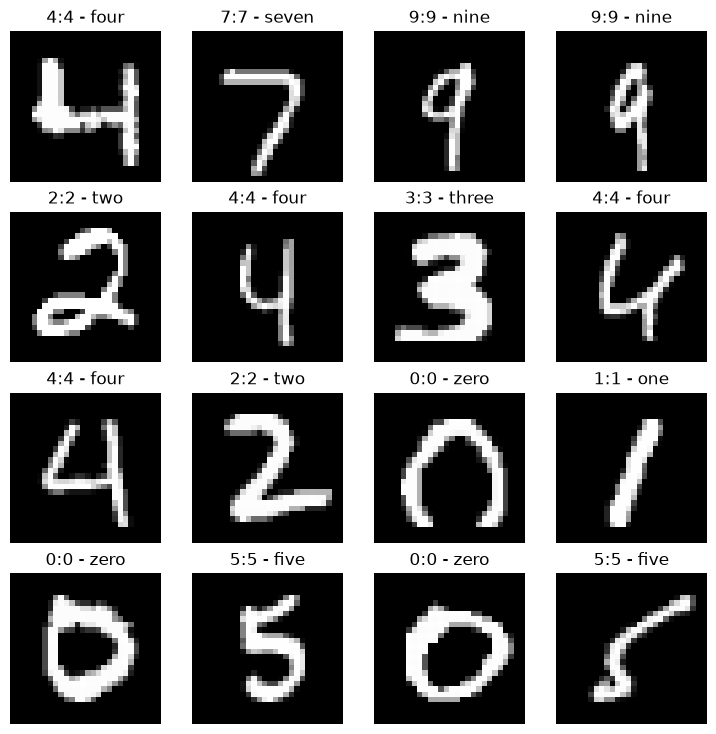

In [4]:
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

import matplotlib.pyplot as plt

random_idxs = torch.randint(0, len(train_data), size=(5,))
train_data[random_idxs[0]]

class_names = train_data.classes

fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4 # print 16 image
for i in range(1, rows*cols +1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  image, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(image.squeeze(), cmap="gray")
  plt.title(f"{label}:{class_names[label]}")
  plt.axis(False)

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True
                              )
test_dataloader = DataLoader(dataset=test_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True
                              )

In [6]:
image, label = train_data[0]
image.shape, label

class_names = train_data.classes

## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [7]:
import torch.nn as nn

class TinyVGGModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units=10):
    super().__init__()
    self.block_1=nn.Sequential(
        nn.Conv2d(in_channels=input_features,
                  out_channels=hidden_units,
                  padding=1,
                  stride=1,
                  kernel_size=3),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  padding=1,
                  stride=1,
                  kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2))

    self.block_2=nn.Sequential(
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                padding=1,
                stride=1,
                kernel_size=3),
      nn.ReLU(),
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                padding=1,
                stride=1,
                kernel_size=3),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2))

    self.classifer=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7,
                  out_features=output_features)
    )

  def forward(self, x):
    return self.classifer(self.block_2(self.block_1(x)))

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [8]:
output_features = len(class_names)

model = TinyVGGModel(input_features=1,
                     output_features=10,
                     hidden_units=10).to(device)

def print_total_time(start:float,
                     end:float):
  total_time = end-start
  print(f"Total time: {total_time:.3f} seconds")
  return total_time



In [9]:
# Try a dummy forward pass to see what shapes our data is
dummy_x = torch.rand(size=(1, 28, 28)).unsqueeze(dim=0).to(device)
# dummy_x.shape
model(dummy_x)

tensor([[-0.0097, -0.0498, -0.0068, -0.0598,  0.0755,  0.0737,  0.0033, -0.0101,
         -0.0307, -0.0212]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [10]:
! pip install torchmetrics

In [21]:
import torch.optim as optim
from torchmetrics import Accuracy

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(params=model.parameters(),
                      lr=0.1)

# Put accuracy function on target device
accuracy_fn = Accuracy(task="multiclass",
                       num_classes=len(class_names)).to(device)


In [12]:

# Build a training loop
from  timeit import default_timer as timer

start = timer()
# start
epoches = 5

for epoch in range(epoches):
  model.train()

  train_loss, train_acc = 0, 0

  for batch_num, (X, y) in enumerate(train_dataloader):
    # Put data on the target device
    X, y = X.to(device), y.to(device)

    y_logits = model(X)
    y_preds = torch.softmax(y_logits, dim=1).argmax(dim=1)

    loss = loss_fn(y_logits, y)
    train_loss += loss
    train_acc += accuracy_fn(y_preds, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)

  # Evaluation loop
  model.eval()
  with torch.inference_mode():
    test_loss, test_acc = 0, 0

    for X_test, y_test in test_dataloader:
      X_test, y_test = X_test.to(device), y_test.to(device)

      y_test_logits = model(X_test)
      y_test_preds = torch.softmax(y_test_logits, dim=1).argmax(dim=1)

      test_loss += loss_fn(y_test_logits, y_test)
      test_acc += accuracy_fn(y_test_preds, y_test)

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"Epoch: {epoch} | Loss: {train_loss:.3f} | Test loss: {test_loss:.3f} | Test acc: {test_acc}")

end = timer()
print_total_time(start, end)

Epoch: 0 | Loss: 0.341 | Test loss: 0.082 | Test acc: 0.9752395749092102
Epoch: 1 | Loss: 0.076 | Test loss: 0.058 | Test acc: 0.9802315831184387
Epoch: 2 | Loss: 0.060 | Test loss: 0.056 | Test acc: 0.9823282361030579
Epoch: 3 | Loss: 0.052 | Test loss: 0.048 | Test acc: 0.9840255379676819
Epoch: 4 | Loss: 0.045 | Test loss: 0.060 | Test acc: 0.9823282361030579
Total time: 98.877 seconds


98.87697303799996

## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

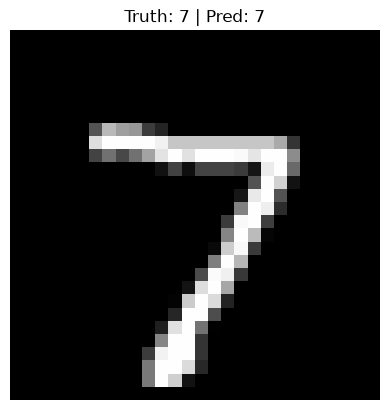

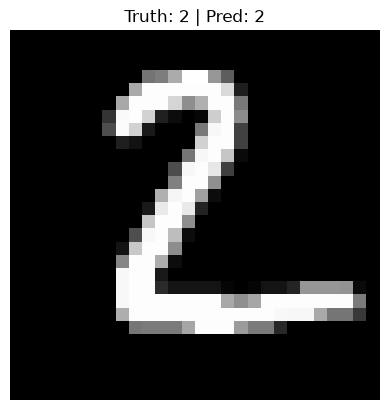

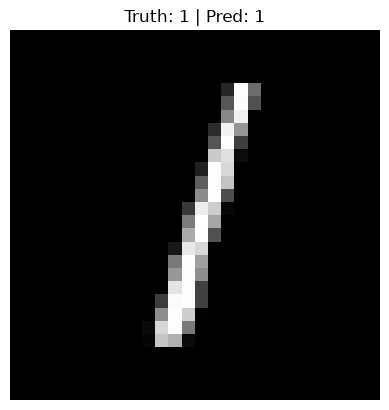

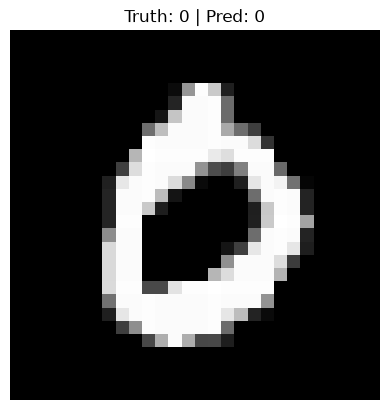

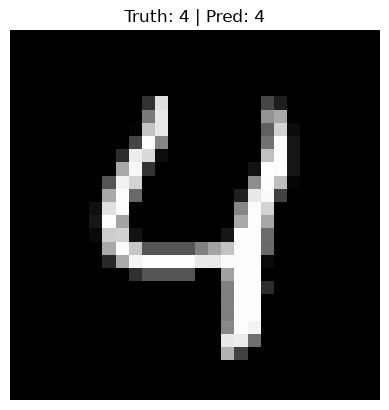

In [13]:

num_to_plot = 5
for i in range(num_to_plot):
  # Get image and labels from the test data
  img = test_data[i][0]
  label = test_data[i][1]

  # Make prediction on image
  model_pred_logits = model(img.unsqueeze(dim=0).to(device))
  model_pred_probs = torch.softmax(model_pred_logits, dim=1)
  model_pred_label = torch.argmax(model_pred_probs, dim=1)

  # Plot the image and prediction
  plt.figure()
  plt.imshow(img.squeeze(), cmap="gray")
  plt.title(f"Truth: {label} | Pred: {model_pred_label.cpu().item()}")
  plt.axis(False);

## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

In [14]:

# See if required packages are installed and if not, install them...
try:
  import torchmetrics, mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")
  assert int(mlxtend.__version__.split(".")[1] >= 19, "mlxtend version should be 0.19.0 or higher")
except:
  !pip install torchmetrics -U mlxtend
  import torchmetrics, mlxtend
  print(f"mlxtend version: {mlxtend.__version__}")

mlxtend version: 0.25.0
mlxtend version: 0.25.0


In [22]:
# Make predictions across the entire test dataset in batches
y_preds = []
model.eval()
with torch.inference_mode():
  for X, y in test_dataloader:
    X = X.to(device)
    y_logits = model(X)
    y_pred_labels = torch.softmax(y_logits, dim=1).argmax(dim=1)
    y_preds.append(y_pred_labels.cpu())

# Concatenate list of predictions into one single tensor
y_preds = torch.cat(y_preds)
y_preds

tensor([6, 9, 5,  ..., 5, 7, 8])

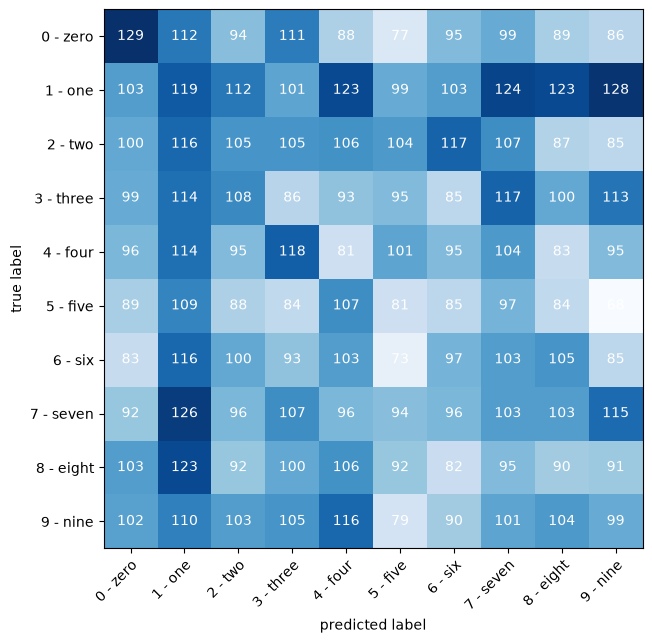

In [ ]:

from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# Setup confusion matrix 
confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds=y_preds,
                         target=test_data.targets)

# Plot the confusion matrix
fix, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=class_names,
    figsize=(10, 7)
)

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

In [25]:
random_tensor = torch.rand(size=(1, 3, 64, 64))
conv_layer = nn.Conv2d(in_channels=3,
                       out_channels=10,
                       kernel_size=3,
                       stride=1)

output_features = conv_layer(random_tensor)
output_features.shape
# random_tensor.shape

torch.Size([1, 10, 62, 62])

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset.
* Then plot some predictions where the model was wrong alongside what the label of the image should've been.
* After visualing these predictions do you think it's more of a modelling error or a data error?
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?